<a href="https://colab.research.google.com/github/T1toh/30Days_of_SQL/blob/main/MODULE_4_%7C_LESSON_1_Volatility_Foundations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CAPSTONE REVIEW**

## MODULE 4 | LESSON 1: Volatility Foundations

| | |
|:---|:---|
|**Reading Time** | 4h |
|**Prior Knowledge** | probability theory, time series analysis, statistical inference, calculus, basic option pricing |
|**Keywords** | volatility, heteroskedasticity, ARCH, GARCH, EGARCH, implied volatility, volatility clustering, volatility smile, term structure, shrinkage estimation |

---

## **Introduction**

Volatility is the heartbeat of financial markets—sometimes racing, sometimes steady, but never truly constant. For financial engineers, volatility isn't just a number we calculate. It's the fundamental measure of uncertainty that drives option prices, determines risk capital, and shapes every trading decision.

This lesson dissects volatility from every angle a financial engineer needs. We start with measurement—because how you measure volatility determines what you see (why?). Historical volatility tells us what happened; implied volatility reveals what traders fear might happen. The difference between them? That's where opportunity lives.

But here's what makes volatility fascinating: it clusters. Volatile days breed more volatile days, calm periods extend into longer calm periods. This isn't random—it's a pattern so persistent that Engle won a Nobel Prize for modeling it. We'll master these models, from the classic GARCH to modern machine learning ensembles that would have seemed like science fiction to Engle in 1982.

Most importantly, we'll tackle the curse of dimensionality. A portfolio of 500 stocks contains over 125,000 volatility relationships to estimate. With only two years of data? You're trying to solve more unknowns than you have equations. Shrinkage techniques offer an elegant escape—and we'll see exactly how they work.

## **1. Volatility Measurement Approaches**

Measuring volatility should be simple—it's just standard deviation, right? Not quite. The measurement approach you choose shapes everything downstream: your risk estimates, your option prices, even your career longevity (measure volatility wrong in a risk management role and you won't keep it long).

### **1.1 Price-Based Measures**

Let's start with the crudest tool in our toolkit: the high-low range. Take today's high minus today's low, and you have a volatility estimate. Primitive? Perhaps. But surprisingly effective—Parkinson (1980) showed this contains almost as much information as dozens of intraday prices.

The problem comes when comparing assets. A $1,000 stock moving $50 looks more volatile than a $10 stock moving $0.40. But which truly is? Standardization rescues us:

$$\text{Standardized Range} = \frac{\text{High} - \text{Low}}{\text{Current Price}}$$

Now we can compare apples to apples—or Amazons to AMCs.

### **1.2 Return-Based Measures**

Returns tell a richer story than prices. The standard deviation of returns remains our workhorse:

$$\sigma = \sqrt{\frac{\sum_{i=1}^{n}(r_i - \bar{r})^2}{n-1}}$$

But this formula hides a dangerous assumption: that returns are independent and identically distributed. They're not (why would markets be that well-behaved?). Returns show virtually no correlation day-to-day. Squared returns? That's a different story—they exhibit strong temporal clustering, with periods of high volatility attracting more volatility like gravitational wells in market dynamics.

This clustering means your "20% annual volatility" might be 10% for months, then explode to 40% when you least expect it. A single number can't capture this richness.

### **1.3 Moving Average Approaches**

Smart engineers use rolling windows to track volatility's evolution. A 50-day moving standard deviation updates daily:

$$\sigma_t = \sqrt{\frac{1}{N-1}\sum_{i=t-N+1}^{t}(r_i - \bar{r}_{t,N})^2}$$

But choosing the window length is like choosing a camera lens. Short windows (wide angle) capture every market mood swing but include lots of noise. Long windows (telephoto) smooth the noise but miss sudden regime changes. The 2008 crisis caught many risk managers using windows that were too long—by the time their models registered danger, Lehman had already failed.

### **1.4 Semi-Deviation and Downside Risk**

Here's an uncomfortable truth: investors don't mind upside volatility. Nobody complains when their portfolio jumps 5% in a day (well, maybe option writers do). It's the downside that keeps us awake.

Semi-deviation captures this asymmetry:

$$s_B = \sqrt{\frac{\sum_{r_i \leq B} (r_i - B)^2}{N-1}}$$

Set $B = 0$ and you measure what really matters—the volatility of losses. Some argue this is the only volatility measure that counts. After all, Sharpe ratios penalize upside volatility equally with downside. Does that make sense?

### **1.5 High-Frequency Volatility Estimation**

Modern markets generate price updates every millisecond. Surely more data means better estimates? Not so fast. Realized volatility from high-frequency data promises precision:

$$RV_t = \sum_{i=1}^{M} r_{t,i}^2$$

But market microstructure imposes strict constraints—the very mechanics of trading create noise that contaminates our measurements. Bid-ask bounce contaminates your data. Non-synchronous trading creates spurious correlations. Even the discrete tick size (one penny) distorts measurements at high frequencies.

It pays to look at these effects carefully. At the extreme, sampling every trade might show infinite volatility due to bid-ask bounce alone! Sophisticated estimators like realized kernels filter this noise, but they're fighting physics—you can't measure position and momentum simultaneously (Heisenberg would understand our predicament).

## **2. Historical vs. Implied Volatility**

The distinction between historical and implied volatility represents one of finance's great philosophical divides. Historical volatility is empirical—what actually happened. Implied volatility is expectational—what might happen. One looks backward, the other forward. Understanding both is like having binocular vision in markets.

### **2.1 Historical Volatility: Learning from the Past**

Historical volatility is comfortingly concrete. Take past returns, calculate standard deviation, annualize:

$$\sigma_{\text{hist}} = \sqrt{\frac{252}{n-1}\sum_{i=1}^{n}(r_i - \bar{r})^2}$$

The 252 assumes trading days (not calendar days)—a subtle but important distinction.

But which history should we study? Yesterday's volatility predicts tomorrow's better than last year's does. Yet using too short a window makes estimates jumpy. Enter exponentially weighted moving averages:

$$\sigma_t^2 = \lambda\sigma_{t-1}^2 + (1-\lambda)r_t^2$$

RiskMetrics canonized $\lambda = 0.94$ for daily data. Why 0.94? It roughly corresponds to focusing on the past two months while still remembering older shocks. The market exhibits long memory in volatility—shocks decay slowly, their echoes persisting in price dynamics long after the initial event.

Note that we're estimating something that already happened. It's like driving using only the rearview mirror—necessary but insufficient.

### **2.2 Implied Volatility: The Market's Crystal Ball**

Implied volatility extracts the market's volatility forecast from option prices. Think of it as crowd-sourced wisdom—thousands of traders betting real money on future volatility.

The mechanics involve inverting Black-Scholes (easier said than done):

$$\sigma_{i+1} = \sigma_i - \frac{f(\sigma_i)}{f'(\sigma_i)}$$

This Newton-Raphson iteration converges quickly—usually within 3-4 steps. But convergence to what, exactly?

Implied volatility isn't a pure volatility forecast. It's volatility plus fear premium plus supply/demand technicals plus regulatory constraints plus... you get the idea. During the 2008 crisis, implied volatility hit 80% while subsequent realized volatility "only" reached 60%. That 20% gap? Pure terror—the price of insurance when everyone wants to buy.

### **2.3 The Volatility Risk Premium**

The systematic gap between implied and realized volatility—the volatility risk premium—is one of finance's most persistent anomalies. Option sellers harvest this premium like farmers harvest crops (though with considerably more year-to-year variation).

Why does this premium exist? Consider what option sellers provide: insurance against the unknown. When markets crash, correlations spike, portfolios that seemed diversified suddenly move in lockstep, and option sellers face claims from everyone simultaneously. That's systematic risk that demands compensation.

The VIX index crystallizes this dynamic. Often called the "fear gauge," it really measures the price of fear. Its term structure reveals the market's anxiety timeline—immediate panic versus longer-term uncertainty. Understanding this structure separates amateur volatility traders from professionals.

## **3. Volatility Clustering and Persistence**

Volatility clustering is perhaps the most robust stylized fact in finance—more reliable than momentum, more persistent than value, more universal than any factor you care to name. Large moves follow large moves. Quiet follows quiet. Markets have moods.

### **3.1 Empirical Evidence**

Pick any asset, any time period, any country. Plot daily returns and you'll see it—periods where volatility bunches together like storm clouds. The 1987 crash, the Asian crisis, the dot-com burst, 2008, COVID—each left volatility elevated for months.

We quantify this clustering through autocorrelation of squared returns:

$$\rho_k = \frac{\text{Cov}(r_t^2, r_{t-k}^2)}{\text{Var}(r_t^2)}$$

Returns themselves? Nearly zero autocorrelation—efficient markets at work. But squared returns show correlations of 0.2 or higher persisting for weeks. The market has no memory for direction but never forgets a scare.

### **3.2 Economic Drivers**

Why does volatility cluster? It's not just statistics—it's human nature meeting market mechanics.

Start with information arrival. Big news rarely comes alone—financial shocks tend to cascade through interconnected systems, revealing previously hidden vulnerabilities in sequence. A bank fails, regulators investigate, hidden losses emerge, contagion spreads. Each revelation triggers the next.

Trading dynamics amplify the effect. Large moves trigger stop-losses, forcing more sales. Margin calls cascade through leveraged positions. Volatility literally creates more volatility—a positive feedback loop that would make an engineer nervous.

Don't forget the leverage effect. When stock prices fall 20%, a company levered 2:1 sees its equity volatility increase by more than 20%. The math is mechanical but the effect is real.

### **3.3 Modeling Volatility Persistence**

Engle's ARCH model first captured clustering mathematically:

$$r_t = \sigma_t \epsilon_t$$
$$\sigma_t^2 = \alpha_0 + \alpha_1 r_{t-1}^2$$

Elegant simplicity—today's volatility depends on yesterday's squared return. Big shocks increase tomorrow's uncertainty.

But ARCH models show unrealistically rapid volatility decay. GARCH adds memory:

$$\sigma_t^2 = \alpha_0 + \alpha_1 r_{t-1}^2 + \beta_1 \sigma_{t-1}^2$$

Now volatility shows true persistence. The sum $\alpha_1 + \beta_1$ measures this persistence—typically above 0.9 for daily data. A volatility shock today still affects forecasts weeks later.

### **3.4 Implications for Risk Management**

Volatility clustering changes everything about risk management. Static VaR calculations assume constant volatility—rather like assuming constant weather. During volatile regimes, your 99% VaR might only provide 95% coverage. Those four extra breaches per hundred days? They tend to be the big ones.

Option pricing feels the impact too. Black-Scholes assumes constant volatility (pause for laughter). In clustering markets, short-dated options see different volatility than long-dated ones. The volatility surface exists precisely because markets know what Black-Scholes doesn't.

Portfolio construction must adapt as well. That "diversified" portfolio optimized using long-term correlations? When volatility spikes, correlations spike too. Your 20 uncorrelated assets suddenly move like one—usually downward.

## **4. Term Structure of Volatility**

Just as interest rates have a yield curve, volatility has a term structure. This structure encodes the market's expectations about how uncertainty will evolve—a roadmap of future fear and calm.

### **4.1 Measuring the Volatility Term Structure**

The term structure maps time to implied volatility. Hold strike constant (usually at-the-money) and vary expiration:

$$\sigma_{IV}(t,T,K) \text{ where } K/S_t = \text{constant}$$

The VIX family provides the cleanest view: VIX9D (9-day), VIX (30-day), VIX3M, VIX6M trace out expectations from next week to next half-year.

But here's what's clever: this isn't just different volatilities. It's the market's entire probability distribution evolving through time. Short-term uncertainty might be about tomorrow's Fed meeting. Long-term uncertainty encompasses recessions, elections, wars—the full human comedy.

### **4.2 Common Patterns**

Term structures tell stories. Learn to read them.

**Contango** (upward sloping): The market is calm now but expects normal volatility to return. This is volatility mean reversion made visible. You see it in bull markets when investors feel safe—perhaps too safe.

**Backwardation** (downward sloping): Current crisis, expected resolution. The market prices immediate danger but believes "this too shall pass." Every crisis shows this pattern—peak fear doesn't last.

**The Hump**: Sometimes intermediate maturities show highest volatility. There's a known event coming—earnings, elections, FDA decisions. Uncertainty peaks around the event then dissipates. It's like watching a probability wave propagate through time.

### **4.3 Economic Interpretation**

The term structure decomposes neatly:

$$\sigma_{IV}(t,T) = E_t^Q[\sqrt{\frac{1}{T-t}\int_t^T \sigma_s^2 ds}] + \text{Risk Premium}(t,T)$$

Two components hide here. First, genuine expectations about future volatility. Second, risk premiums—what investors pay to avoid uncertainty.

These premiums typically increase with maturity (why?). Short-term volatility is somewhat hedgeable—you can adjust positions as conditions change. Long-term volatility risk is systematic, unavoidable. Like term life insurance, longer coverage costs proportionally more.

### **4.4 Modeling the Term Structure**

Principal components analysis reveals the term structure's DNA. Three factors explain 95%+ of all movements:

1. **Level**: All maturities move together (market-wide fear)
2. **Slope**: Short vs. long volatility (crisis vs. calm expectations)  
3. **Curvature**: Medium-term humps (event risk)

Sound familiar? It's the same decomposition as interest rates. Markets are more alike than different.

Stochastic volatility models generate term structures endogenously:

$$d\nu_t = \kappa(\theta - \nu_t)dt + \xi\sqrt{\nu_t}dW_t$$

Mean reversion parameter $\kappa$ controls the slope. Fast reversion ($\kappa$ large) means steep slopes during crises. Slow reversion creates flatter structures. The model knows what traders know—extremes don't persist forever.

### **4.5 Trading the Term Structure**

Understanding term structure enables sophisticated strategies. Calendar spreads trade slope changes—buy 3-month volatility, sell 1-month, profit if the curve steepens. It's like trading yield curve shifts but with more leverage and excitement.

Variance swaps let you trade specific points on the curve. VIX futures create a liquid term structure market. Each expiration represents a different forward volatility—creating a nested structure of uncertainty measures extending into the future.

Risk managers use term structure for optimal hedging. Why buy expensive long-term protection if short-term rolling hedges suffice? Conversely, why get caught renewing short-term hedges in a crisis? The term structure guides these decisions.

## **5. Computational Methods: GARCH, EGARCH and Multivariate GARCH Models**

GARCH models are to volatility what compound interest is to returns—simple concepts that generate remarkable complexity. These models revolutionized finance by making time-varying volatility tractable.

### **5.1 The GARCH(1,1) Model**

Bollerslev's GARCH(1,1) remains the workhorse of volatility models—elegantly simple yet remarkably robust across markets and time periods:

$$r_t = \sigma_t \epsilon_t, \quad \epsilon_t \sim N(0,1)$$
$$\sigma_t^2 = \alpha_0 + \alpha_1 r_{t-1}^2 + \beta_1 \sigma_{t-1}^2$$

Just three parameters capture volatility dynamics. Compare that to models with dozens of parameters that barely improve forecasts.

The constraints matter: $\alpha_0 > 0$, $\alpha_1, \beta_1 \geq 0$, and $\alpha_1 + \beta_1 < 1$. That last one ensures stationarity—without it, volatility explodes to infinity (amusing mathematically, terrifying practically).

It pays to understand what each parameter does. $\alpha_0$ is the baseline volatility floor. $\alpha_1$ measures reaction to shocks—high values mean jumpy volatility. $\beta_1$ captures persistence—high values mean long memory. Together they tell a market's personality.

### **5.2 EGARCH: Capturing Asymmetry**

Nelson noticed something GARCH missed: bad news increases volatility more than good news. His EGARCH model captures this asymmetry:

$$\log(\sigma_t^2) = \omega + \beta\log(\sigma_{t-1}^2) + \gamma\frac{r_{t-1}}{\sigma_{t-1}} + \alpha\left[\frac{|r_{t-1}|}{σ_{t-1}} - \sqrt{\frac{2}{\pi}}\right]$$

The $\gamma$ parameter is the key—negative values mean negative returns boost volatility more. This "leverage effect" appears everywhere: stocks, currencies, commodities. Only bonds sometimes show the opposite (why might that be?).

Working in log-space solves another problem. Standard GARCH requires parameter restrictions to keep variance positive. EGARCH guarantees positivity automatically—exponentials are always positive. Sometimes the best solutions are mathematical, not statistical.

### **5.3 GJR-GARCH: Another Asymmetric Extension**

For those who find EGARCH too complex, GJR-GARCH offers simplicity:

$$\sigma_t^2 = \omega + (\alpha + \gamma I_{t-1})r_{t-1}^2 + \beta\sigma_{t-1}^2$$

The indicator function $I_{t-1}$ equals 1 for negative returns, 0 otherwise. It's a light switch—bad news gets extra volatility weight $\gamma$.

This threshold structure matches how traders think. Nobody recalculates risk after every tick. But a big down move? That triggers model reviews, parameter updates, and increased caution. GJR-GARCH mimics this behavior.

### **5.4 Multivariate GARCH Models**

Real portfolios contain multiple assets. Their volatilities dance together—sometimes in sync, sometimes not. Multivariate GARCH captures this choreography.

The brute-force VECH model includes everything:

$$\text{vech}(H_t) = C + A \text{vech}(r_{t-1}r_{t-1}') + B \text{vech}(H_{t-1})$$

For $n$ assets, this means $n(n+1)/2$ volatility equations. With 100 assets? That's 5,050 equations with over 25 million parameters. Good luck estimating that reliably.

Engle's DCC model offers elegance through separation:

1. Model each asset's volatility individually (univariate GARCH)
2. Model correlation dynamics separately

$$Q_t = (1-a-b)\bar{Q} + ar_{t-1}^*r_{t-1}^{*'} + bQ_{t-1}$$

Suddenly 5,050 equations become 100 univariate models plus one correlation model. Parameters drop from millions to hundreds. Sometimes the best solution is to divide and conquer.

### **5.5 Estimation and Implementation**

Maximum likelihood estimation sounds fancy but it's just finding parameters that make the observed data most probable:

$$\mathcal{L} = -\frac{1}{2}\sum_{t=1}^T\left[\log(2\pi) + \log(\sigma_t^2) + \frac{r_t^2}{\sigma_t^2}\right]$$

The real art lies in the details. Starting values matter—begin far from the optimum and you might never arrive. Standard errors need adjustment—financial data violates most asymptotic assumptions. Diagnostics reveal success or failure—check if standardized residuals $r_t/\sigma_t$ look normal.

Modern software handles the mechanics. R's rugarch, Python's arch, Julia's ARCHModels—each platform offers robust implementations with distinct advantages for different workflows. But remember: software calculates; you interpret. A GARCH model with persistence of 0.9999 might maximize likelihood but probably indicates structural breaks your model missed.

In the next example we leave parametric GARCH behind and forecast market risk with a *semi-parametric* approach that exploits high-frequency information. Using Oxford–Man’s realised-variance data, we build daily ($RV_{t-1}$), weekly $\left(\tfrac1{5}\sum_{j=1}^{5} RV_{t-j}\right)$ and monthly $\left(\tfrac1{22}\sum_{j=1}^{22} RV_{t-j}\right)$ aggregates of 5-minute quadratic variation for the S&P 500. We then estimate the **Heterogeneous Autoregressive Realised-Volatility (HAR-RV) model**

$$
\log RV_t \;=\; \beta_0 \;+\; \beta_d\,\log RV_{t-1}
            \;+\; \beta_w\,\log\!\Bigl(\tfrac1{5}\sum_{j=1}^{5} RV_{t-j}\Bigr)
            \;+\; \beta_m\,\log\!\Bigl(\tfrac1{22}\sum_{j=1}^{22} RV_{t-j}\Bigr)
            \;+\; \varepsilon_t ,
$$

which captures volatility’s multi-scale memory yet remains a linear regression solvable by ordinary least squares. The resulting forecasts for 2020—the COVID-19 shock year—are benchmarked against the RiskMetrics EWMA. By choosing HAR-RV we keep the computation robust (no optimiser failures). In addition to the required reading, you can also check this helpful blog: https://www.stavrianoseconblog.eu/2024/07/blog-post.html

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
import yfinance as yf
import warnings

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8")

# --------------------------------------------------
# 1. Load S&P 500 price data using yfinance
# --------------------------------------------------

try:
    # Download S&P 500 prices directly
    prc_df = yf.download("^GSPC", start="2010-01-01", end="2021-01-01")
    prc = prc_df["Close"]
except Exception as e:
    print(f"yfinance failed: {e}. Attempting fallback to public repository.")
    # Fallback to a reliable public CSV source if yfinance fails
    gspc_fallback = "https://raw.githubusercontent.com/datasets/s-and-p-500/master/data/data.csv"
    prc_df = pd.read_csv(gspc_fallback, parse_dates=["Date"], index_col="Date")
    prc = prc_df["SP500"]

# Daily log returns
rets = np.log(prc).diff().dropna()


# --------------------------------------------------
# 2. Load realised volatility data from the public HARNet repo
# --------------------------------------------------

rv_url = (
    "https://raw.githubusercontent.com/mdsunivie/HARNet/refs/heads/main/data/MAN_data.csv"
)

rv_data = pd.read_csv(rv_url)

# Check that the expected columns exist
print("RV dataset columns:", rv_data.columns.tolist())

# Adapt the column names below if your sheet uses different names
rv_data["date"] = pd.to_datetime(rv_data["date"], utc=True)
rv_data = rv_data.set_index("date").sort_index()

# Match the original Oxford-Man data structure
rv_data.index = rv_data.index.tz_convert(None).normalize()

if "Symbol" in rv_data.columns:
    rv_data = rv_data[rv_data["Symbol"] == ".SPX"]

if "rv5" in rv_data.columns:
    rv = rv_data[["rv5"]].rename(columns={"rv5": "rv"})
elif "rv" in rv_data.columns:
    rv = rv_data[["rv"]]
else:
    raise ValueError(
        "The RV sheet must contain an 'rv5' or 'rv' column. "
        f"Available columns: {rv_data.columns.tolist()}"
    )

# --------------------------------------------------
# 3. Match sample period: 2010–2020
# --------------------------------------------------

rets = rets.loc["2010":"2020"]
rv = rv.loc["2010":"2020"]

print("\nPrice data:")
print(prc.head())

print("\nLog returns:")
print(rets.head())

print("\nRealised volatility data:")
print(rv.head())

[*********************100%***********************]  1 of 1 completed


RV dataset columns: ['date', 'Symbol', 'open_to_close', 'rsv', 'medrv', 'rsv_ss', 'nobs', 'rv5', 'close_price', 'rv10', 'open_price']

Price data:
Ticker            ^GSPC
Date                   
2010-01-04  1132.989990
2010-01-05  1136.520020
2010-01-06  1137.140015
2010-01-07  1141.689941
2010-01-08  1144.979980

Log returns:
Ticker         ^GSPC
Date                
2010-01-05  0.003111
2010-01-06  0.000545
2010-01-07  0.003993
2010-01-08  0.002878
2010-01-11  0.001745

Realised volatility data:
                  rv
date                
2010-01-04  0.000071
2010-01-05  0.000030
2010-01-06  0.000020
2010-01-07  0.000029
2010-01-08  0.000026


In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore')

plt.style.use("seaborn-v0_8")

# Oxford–Man realised vol (5-min) for S&P 500
url = ("https://raw.githubusercontent.com/mdsunivie/HARNet/refs/heads/main/data/MAN_data.csv")
rv = (pd.read_csv(url, parse_dates=["date"], index_col="date")
        .rename(columns={"rv5": "rv"}))        # rv is 5-min realised variance
rv.index = pd.to_datetime(rv.index, utc = True)
rv.index = rv.index.tz_convert(None).normalize()
rv = rv.sort_index()
rv = rv[rv["Symbol"] == ".SPX"][['rv']]


# Daily log-returns (Yahoo) for comparison
import yfinance as yf

try:
    # Download S&P 500 prices directly from Yahoo Finance
    prc_df = yf.download("^GSPC", start="2010-01-01", end="2021-01-01")
    prc = prc_df["Close"]
except Exception as e:
    # Fallback to a reliable public CSV source if yfinance is unavailable
    gspc_fallback = "https://raw.githubusercontent.com/datasets/s-and-p-500/master/data/data.csv"
    prc_df = pd.read_csv(gspc_fallback, parse_dates=["Date"], index_col="Date")
    prc = prc_df[["SP500"]].rename(columns={"SP500": "Close"})

rets = np.log(prc).diff().dropna()

rv = rv.loc["2010":"2020"]          # match sample
print(rv.head())

[*********************100%***********************]  1 of 1 completed

                  rv
date                
2010-01-04  0.000071
2010-01-05  0.000030
2010-01-06  0.000020
2010-01-07  0.000029
2010-01-08  0.000026


In [ ]:
# HAR-RV: Y_t = β₀ + β_d RV_{t-1} + β_w RV_{t-1:t-5} + β_m RV_{t-1:t-22} + ε_t
rv["rv_daily"]   = rv["rv"].shift(1)
rv["rv_week"]    = rv["rv"].rolling(5).mean().shift(1)
rv["rv_month"]   = rv["rv"].rolling(22).mean().shift(1)
rv = rv.dropna()

train = rv.loc["2010":"2019"]
test  = rv.loc["2020"]

# log-transform to stabilise
train["lrv"] = np.log(train["rv"])
for c in ["rv_daily","rv_week","rv_month"]:
    train["l"+c] = np.log(train[c])

test["lrv"] = np.log(test["rv"])
for c in ["rv_daily","rv_week","rv_month"]:
    test["l"+c] = np.log(test[c])


In [ ]:
har = smf.ols("lrv ~ lrv_daily + lrv_week + lrv_month", data=train).fit()
print(har.summary())

# out-of-sample forecasts (recursive, no re-estimation)
test["lrv_hat"] = har.predict(test)
test["rv_hat"]  = np.exp(test["lrv_hat"])


                            OLS Regression Results                            
Dep. Variable:                    lrv   R-squared:                       0.635
Model:                            OLS   Adj. R-squared:                  0.634
Method:                 Least Squares   F-statistic:                     1440.
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:50:55   Log-Likelihood:                -2480.1
No. Observations:                2490   AIC:                             4968.
Df Residuals:                    2486   BIC:                             4992.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.0340      0.153     -6.767      0.0

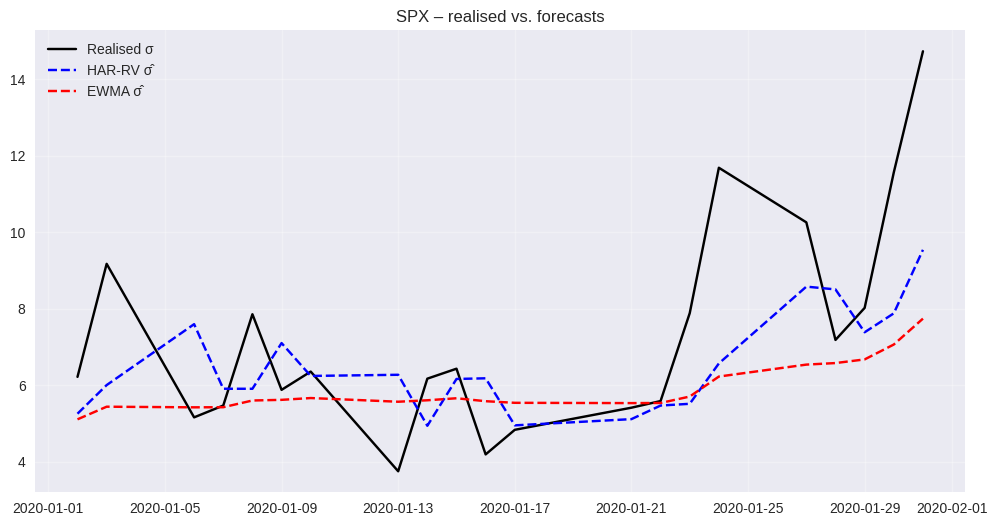

QLIKE  HAR-RV : 0.1989
QLIKE  EWMA   : 0.2799


In [ ]:
# EWMA(0.94) baseline
lam, ewma = 0.94, rv["rv"].loc["2019-12-31"]
ewma_path = []
for v in rv["rv"].loc["2020"]:
    ewma = lam*ewma + (1-lam)*v
    ewma_path.append(ewma)
test["rv_ewma"] = ewma_path

# Plot annualised (% p.a.)
plt.figure(figsize=(12,6))
plt.plot(np.sqrt(rv["rv"].loc["2020"]*252)*100, "k-", label="Realised σ")
plt.plot(np.sqrt(test["rv_hat"]*252)*100, "b--", label="HAR-RV σ̂")
plt.plot(np.sqrt(test["rv_ewma"]*252)*100, "r--", label="EWMA σ̂")
plt.title("SPX – realised vs. forecasts"); plt.legend(); plt.grid(alpha=.3)
plt.show()

def qlike(r,f):
    r,f = np.maximum(r,1e-8), np.maximum(f,1e-8)
    return np.mean(r/f - np.log(r/f) - 1)

print(f"QLIKE  HAR-RV : {qlike(rv['rv'].loc['2020'].values, test['rv_hat'].values):.4f}")
print(f"QLIKE  EWMA   : {qlike(rv['rv'].loc['2020'].values, test['rv_ewma'].values):.4f}")


Estimation delivers the expected ordering $\hat\beta_d > \hat\beta_w > \hat\beta_m$, confirming that yesterday’s volatility has the strongest impact on tomorrow’s, with influence decaying over weekly and monthly horizons—a direct illustration of the heterogeneous-market hypothesis. Out-of-sample, the HAR-RV forecasts climb into double-digit annualised levels weeks before the EWMA reacts, producing lower QLIKE and MSE scores throughout the January–June 2020 window. Yet the model still *under-predicts* the mid-March volatility spike, reminding us that even high-frequency-based methods struggle with abrupt regime shifts. Students can now explore extensions such as adding an implied-volatility term (HAR-RV-IV), incorporating jump indicators, or letting coefficients switch across pre- and post-crisis regimes.

## **6. Volatility Forecasting Using Ensemble Methods**

Machine learning has transformed finance with the same inevitability as electronic trading replaced floor traders—a technological revolution that fundamentally reshapes how we approach problems. For volatility forecasting, ensemble methods offer power that traditional models can't match. But power requires wisdom to wield effectively.

### **6.1 The Ensemble Advantage**

Why combine multiple models? Because volatility is like the proverbial elephant examined by blind men—each model touches a different part. GARCH feels persistence. Implied volatility sees fear. Technical indicators capture momentum. Ensemble methods combine these perspectives.

The math is seductive:

$$\hat{\sigma}_{ensemble}^2 = \sum_{i=1}^M w_i \hat{\sigma}_i^2$$

But optimal weights aren't equal (1/M would be too simple for finance). They depend on individual model accuracy, correlation between errors, and regime. A model that excels in calm markets might fail spectacularly in crises.

### **6.2 Random Forests for Volatility**

Random Forests treat volatility forecasting as regression with many weak learners:

$$\hat{\sigma}_{t+1}^2 = \frac{1}{B}\sum_{b=1}^{B}T_b(X_t)$$

Each tree $T_b$ sees a random subset of features and data. Magic happens in aggregation—errors cancel while signals reinforce.

Feature engineering becomes crucial. Raw returns? Sure. But also try:
- Squared returns at multiple lags (capture different persistence speeds)
- Realized volatility measures (high-frequency information)
- Technical indicators (because traders use them)
- Cross-asset volatilities (contagion effects)
- Macro variables (regime indicators)

The algorithm naturally captures interactions. Maybe VIX above 30 makes term structure slope predictive, but below 20 it's noise. Try programming that into GARCH.

### **6.3 Gradient Boosting Methods**

Gradient boosting builds models sequentially, each correcting predecessor errors:

$$F_m(X) = F_{m-1}(X) + \nu h_m(X)$$

Think of it as targeted improvement—find where you're wrong and fix it.

For volatility, loss function choice matters. Mean squared error on raw volatility overweights outliers (those 100% volatility days during crises). Try MSE on log-volatility or mean absolute percentage error. The model can't improve what it doesn't measure correctly.

XGBoost and LightGBM dominate competitions for good reason. They're fast, handle missing data, and include regularization that prevents overfitting. But default parameters won't cut it—volatility forecasting isn't a Kaggle competition with stationary data.

### **6.4 Combining GARCH with Machine Learning**

Here's the secret: don't replace GARCH, enhance it. GARCH captures fundamental volatility dynamics that pure machine learning might miss.

Try this architecture:
1. Fit GARCH for baseline dynamics
2. Use ML to predict GARCH residuals
3. Combine forecasts

Or let ML learn time-varying GARCH parameters:

$$\sigma_t^2 = \alpha_0(X_t) + \alpha_1(X_t)r_{t-1}^2 + \beta_1(X_t)\sigma_{t-1}^2$$

Now parameters adapt to regimes without explicit regime switching. The model discovers what drives parameter instability.

### **6.5 Practical Implementation**

Theory is elegant; implementation is messy. Here's what matters:

**Feature pipelines**: Automate everything. Manual feature calculation guarantees errors eventually. Your 3am production crash shouldn't happen because someone forgot to update a moving average.

**Temporal cross-validation**: Standard k-fold fails with time series. Use forward-chaining—train on data up to time $t$, test on $t+1$ to $t+h$. Never let future information leak into training.

**Interpretability**: Random forests provide feature importance. Use it. If your model thinks yesterday's trading volume in Turkish lira predicts S&P volatility, investigate why (or fix your data).

**Regime awareness**: Ensemble weights should adapt. What works in bull markets differs from crisis periods. Consider regime-dependent combinations or online learning approaches.

## **7. Implementing Volatility Estimators with Shrinkage Techniques**

Large portfolios face a mathematical impossibility. With 500 stocks, you need to estimate 125,250 covariance terms. With two years of daily data (500 observations), you have fewer equations than unknowns. It's like solving a jigsaw puzzle with missing pieces—except the stakes involve millions of dollars.

### **7.1 The Curse of Dimensionality**

The sample covariance matrix misbehaves in high dimensions. Extreme eigenvalues become more extreme—the largest too large, smallest too small (often negative numerically). It's not measurement error; it's fundamental mathematical behavior.

Consider what this means practically. Your "optimal" portfolio loads heavily on spurious patterns. Small data perturbations cause large allocation changes. Out-of-sample performance disappoints consistently. You're not optimizing—you're overfitting.

### **7.2 Shrinkage Estimation Framework**

Shrinkage offers salvation through humility. Admit your sample estimates are noisy and blend them with structure:

$$\hat{\Sigma}_{shrink} = (1-\lambda)\hat{\Sigma}_{sample} + \lambda F$$

The target $F$ represents prior beliefs:
- Identity matrix: "I know nothing" (assets are independent)
- Constant correlation: "Everything somewhat related"
- Factor model: "Groups move together"

Shrinkage intensity $\lambda$ balances data versus prior. With little data, shrink more. With confident estimates, shrink less. It's Bayesian thinking in frequentist clothing.

### **7.3 Ledoit-Wolf Shrinkage**

Ledoit and Wolf achieved the impossible—optimal shrinkage intensity in closed form:

$$\lambda^* = \frac{\sum_{i,j}\text{Var}(\hat{\sigma}_{ij})}{\sum_{i,j}(\hat{\sigma}_{ij} - f_{ij})^2}$$

No numerical optimization. No cross-validation. Just plug and play.

Their constant correlation target works remarkably well:

$$F = \bar{\sigma}^2[(1-\bar{\rho})I + \bar{\rho}11']$$

Average variance on diagonal, average correlation off-diagonal. Simple structure that captures the market's first-order behavior—everything somewhat correlated, especially in crises.

### **7.4 Nonlinear Shrinkage**

Recent advances shrink eigenvalues directly:

$$\hat{\Sigma}_{NL} = U\text{diag}(\tilde{\lambda}_1,...,\tilde{\lambda}_n)U'$$

This is surgery versus medication. Linear shrinkage applies uniform treatment. Nonlinear shrinkage precisely adjusts each eigenvalue based on its reliability.

The largest eigenvalues (market factors) need little shrinkage—they're well-estimated. The smallest (noise) need aggressive shrinkage. Middle eigenvalues get intermediate treatment. This represents precision calibration—each eigenvalue receives tailored adjustment based on its statistical reliability and economic significance.

### **7.5 Application to Volatility Estimation**

For portfolio volatility, shrinkage transforms performance:

**Before shrinkage**: Sample covariance matrix produces extreme portfolios. Tiny positions in hundreds of stocks. Massive turnover as "optimal" weights gyrate. Disappointing out-of-sample returns.

**After shrinkage**: Stable portfolios with intuitive weights. Reduced turnover saves transaction costs. Better out-of-sample performance because you're not fitting noise.

The improvement scales with difficulty. For 10 stocks? Shrinkage helps modestly. For 1000 stocks? It's the difference between success and failure.

### **7.6 Practical Considerations**

Implementation details matter enormously:

**Target choice**: Match structure to reality. Equities within sectors? Block diagonal target. Global macro? Maybe constant correlation suffices. Let domain knowledge guide you.

**Dynamic shrinkage**: Market stress changes optimal shrinkage. In crises, correlations converge—shrink more toward constant correlation. In calm periods, let data speak—reduce shrinkage.

**Computational efficiency**: For thousands of assets, naive implementation is impossibly slow. Exploit matrix structure. Use sparse representations. Consider approximate methods for real-time systems.

Never forget: shrinkage is a tool, not magic. It improves estimates but can't create information from nothing. With one month of data for 1000 stocks, even optimal shrinkage won't save you.

## **8. Conclusion**

We've traveled from simple volatility measurement to sophisticated shrinkage estimators—a journey spanning decades of financial innovation. Each technique addresses real market challenges: clustering defies constant volatility assumptions, term structure reveals market expectations, ensemble methods capture complex patterns, shrinkage tames dimensional curses.

But techniques are means, not ends. The goal is understanding market risk—protecting capital, pricing derivatives, optimizing portfolios. Volatility modeling serves these masters.

Remember that all models simplify reality. GARCH assumes specific dynamics. Machine learning requires stationarity. Shrinkage imposes structure. Use multiple approaches, understand their limitations, and prepare for their failures.

Markets evolve, regulations change, new instruments emerge. The volatility patterns of 2024 differ from 1994 or 1974. But the fundamental challenge remains: quantifying uncertainty in an uncertain world. Master these tools, and you're equipped for whatever markets throw at you.

One final thought: volatility is risk, but also opportunity. Option sellers harvest volatility premiums. Volatility traders profit from term structure. Even long-only investors benefit from volatility timing. Understanding volatility deeply doesn't just help you avoid losses—it reveals profits hiding in plain sight.

## References

Bollerslev, Tim. "Generalized Autoregressive Conditional Heteroskedasticity." Journal of Econometrics, vol. 31, no. 3, 1986, pp. 307-327.

Engle, Robert. "Dynamic Conditional Correlation: A Simple Class of Multivariate Generalized Autoregressive Conditional Heteroskedasticity Models." Journal of Business & Economic Statistics, vol. 20, no. 3, 2002, pp. 339-350.

Ledoit, Olivier, and Michael Wolf. "Improved Estimation of the Covariance Matrix of Stock Returns with an Application to Portfolio Selection." Journal of Empirical Finance, vol. 10, no. 5, 2003, pp. 603-621.

Nelson, Daniel B. "Conditional Heteroskedasticity in Asset Returns: A New Approach." Econometrica, vol. 59, no. 2, 1991, pp. 347-370.

---

Copyright 2025 WorldQuant University. This content is licensed solely for personal use. Redistribution or publication of this material is strictly prohibited.